## 1. Memuat Dataset Hasil Cleaning

Dataset yang telah melalui tahap data cleaning dimuat kembali untuk proses Exploratory Data Analysis (EDA). Pada tahap ini, analisis difokuskan pada transaksi yang berstatus Selesai untuk memastikan bahwa perhitungan penjualan dan pendapatan tidak memasukkan pesanan yang dibatalkan atau belum selesai.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Membaca dataset hasil cleaning
df = pd.read_csv("../data/clean/indonesia_ecommerce_sales_clean.csv")

# Memastikan tipe data sesuai
df["order_date"] = pd.to_datetime(
    df["order_date"], errors="coerce"
)

# Memisahkan transaksi selesai
df_selesai = df[
    df["status_pesanan"].str.strip().str.lower()
    == "selesai"
].copy()

print("Ukuran dataset:", df.shape)
print("Jumlah transaksi selesai:", len(df_selesai))

display(df_selesai.head())

Ukuran dataset: (18868, 19)
Jumlah transaksi selesai: 16045


,order_id,total_qty,total_weight_gr,total_returned_qty,total_diskon,product_categories,num_product_categories,status_pesanan,alasan_pembatalan,opsi_pengiriman,metode_pembayaran,kota_kabupaten,provinsi,ongkos_kirim_dibayar_oleh_pembeli,estimasi_potongan_biaya_pengiriman,total_pembayaran,perkiraan_ongkos_kirim,waktu_pesanan_dibuat,order_date
0,ORD_0000001,2.0,2000,0,0,Celengan,1,Selesai,Tidak dibatalkan,Reguler (Cashless)-SPX Standard,Saldo ShopeePay,KOTA SERANG,BANTEN,0,10000,38300,10000,2024-04-01 00:15:00,2024-04-01
1,ORD_0000002,1.0,500,0,0,Celengan,1,Selesai,Tidak dibatalkan,Hemat Kargo-SPX Hemat,COD (Bayar di Tempat),KOTA SEMARANG,JAWA TENGAH,0,14500,18576,14500,2024-04-01 01:47:00,2024-04-01
2,ORD_0000003,1.0,500,0,0,Celengan,1,Selesai,Tidak dibatalkan,Hemat Kargo-SPX Hemat,SeaBank Bayar Instan,KAB. BOGOR,JAWA BARAT,0,8000,7069,8000,2024-04-01 04:25:00,2024-04-01
3,ORD_0000004,2.0,400,0,0,Mangkok Sambal / Saus,1,Selesai,Tidak dibatalkan,Hemat Kargo-SPX Hemat,COD (Bayar di Tempat),KOTA JAMBI,JAMBI,0,20000,32200,20000,2024-04-01 04:41:00,2024-04-01
5,ORD_0000006,2.0,1000,0,0,Celengan,1,Selesai,Tidak dibatalkan,Hemat Kargo-SPX Hemat,SPayLater,KAB. BANDUNG,JAWA BARAT,0,10000,40996,10000,2024-04-01 07:09:00,2024-04-01


## 2. Pemeriksaan Data untuk Analisis

Pemeriksaan dilakukan untuk memastikan ketersediaan data yang diperlukan dalam menjawab tiga pertanyaan analisis. Pemeriksaan mencakup jumlah transaksi selesai, data tanggal yang tersedia, kategori produk, dan nilai pembayaran. Data dengan tanggal kosong tidak digunakan dalam analisis tren tahunan, sedangkan data dengan jumlah barang kosong tidak digunakan untuk perhitungan kuantitas.

In [2]:
# Ringkasan data transaksi selesai
print("Missing values pada kolom analisis:")

kolom_analisis = [
    "order_id",
    "product_categories",
    "total_qty",
    "total_pembayaran",
    "order_date",
    "kota_kabupaten"
]

display(df_selesai[kolom_analisis].isnull().sum())

# Statistik pembayaran
display(
    df_selesai["total_pembayaran"].describe()
)

# Jumlah kategori yang tercatat
print(
    "Jumlah variasi kategori:",
    df_selesai["product_categories"].nunique()
)

# Rentang tanggal transaksi selesai
print(
    "Tanggal awal:",
    df_selesai["order_date"].min()
)
print(
    "Tanggal akhir:",
    df_selesai["order_date"].max()
)

Missing values pada kolom analisis:


order_id                0
product_categories      0
total_qty             235
total_pembayaran        0
order_date            504
kota_kabupaten          0
dtype: int64

count    1.604500e+04
mean     5.926854e+04
std      1.527066e+05
min      0.000000e+00
25%      1.790000e+04
50%      2.689600e+04
75%      4.821800e+04
max      3.076000e+06
Name: total_pembayaran, dtype: float64

Jumlah variasi kategori: 583
Tanggal awal: 2023-12-01 00:00:00
Tanggal akhir: 2025-11-27 00:00:00


## 3. Analisis Pendapatan Berdasarkan Kategori Produk

Analisis ini bertujuan mengetahui kategori produk yang menghasilkan pendapatan tertinggi. Pendapatan dihitung dengan menjumlahkan `total_pembayaran` pada transaksi yang telah selesai.

Karena satu transaksi dapat mencakup lebih dari satu kategori, analisis utama menggunakan transaksi dengan satu kategori produk agar nilai pembayaran dapat diatribusikan tanpa pembagian atau penggandaan nilai secara sembarang. Transaksi dengan kategori gabungan tidak dimasukkan ke peringkat pendapatan kategori karena rincian nilai pembayaran setiap kategori tidak tersedia.

In [3]:
# Mengambil transaksi dengan satu kategori produk
df_pendapatan = df_selesai[
    df_selesai["product_categories"].notna()
    & df_selesai["total_pembayaran"].notna()
    & ~df_selesai["product_categories"]
        .astype("string")
        .str.contains(",", regex=False)
].copy()

# Menghitung pendapatan setiap kategori
pendapatan_kategori = (
    df_pendapatan
    .groupby("product_categories")
    .agg(
        total_pendapatan=("total_pembayaran", "sum"),
        jumlah_transaksi=("order_id", "nunique")
    )
    .reset_index()
    .sort_values("total_pendapatan", ascending=False)
)

print("10 kategori dengan pendapatan tertinggi:")
display(pendapatan_kategori.head(10))

# Menampilkan kategori dengan pendapatan tertinggi
if not pendapatan_kategori.empty:
    teratas = pendapatan_kategori.iloc[0]

    print(
        "Kategori pendapatan tertinggi:",
        teratas["product_categories"]
    )
    print(
        "Total pendapatan:",
        f"Rp{teratas['total_pendapatan']:,.0f}"
    )

10 kategori dengan pendapatan tertinggi:


,product_categories,total_pendapatan,jumlah_transaksi
28,Seal / Baut / Roof,245458553,492
7,Celengan,133958862,4496
14,Mangkok Sambal / Saus,113711488,2775
15,Nampan / Tray,87516039,968
12,Lunch Box / Rantang,43492911,393
16,Other,33447380,370
5,Baskom / Mangkok Besar,32210334,444
25,Rak / Rak Serbaguna,31218023,390
3,Aksesoris Pintu,30593059,2114
11,Keranjang,13417601,371


Kategori pendapatan tertinggi: Seal / Baut / Roof
Total pendapatan: Rp245,458,553


## 4. Analisis Tren Penjualan Tahunan

Analisis tren penjualan tahunan dilakukan untuk mengetahui perubahan nilai penjualan dari tahun ke tahun. Data yang digunakan merupakan transaksi berstatus Selesai dan memiliki tanggal transaksi yang valid.

Tahun diperoleh dari kolom `order_date`. Selanjutnya, jumlah transaksi unik dan total pembayaran dijumlahkan berdasarkan tahun untuk melihat perkembangan aktivitas penjualan dan pendapatan.

In [4]:
# Menyiapkan data dengan tanggal valid
df_tren = df_selesai.dropna(
    subset=["order_date", "total_pembayaran"]
).copy()

# Mengambil tahun transaksi
df_tren["tahun"] = df_tren["order_date"].dt.year

# Menghitung penjualan per tahun
tren_tahunan = (
    df_tren
    .groupby("tahun")
    .agg(
        jumlah_transaksi=("order_id", "nunique"),
        total_penjualan=("total_pembayaran", "sum")
    )
    .reset_index()
    .sort_values("tahun")
)

print("Tren penjualan tahunan:")
display(tren_tahunan)

# Menghitung perubahan persentase tahunan
tren_tahunan["perubahan_persen"] = (
    tren_tahunan["total_penjualan"]
    .pct_change()
    .mul(100)
)

display(tren_tahunan)

Tren penjualan tahunan:


,tahun,jumlah_transaksi,total_penjualan
0,2023,343,23357121
1,2024,7510,478801256
2,2025,7688,424677937


,tahun,jumlah_transaksi,total_penjualan,perubahan_persen
0,2023,343,23357121,NaN
1,2024,7510,478801256,1949.915553
2,2025,7688,424677937,-11.303922


## 5. Analisis Kategori Produk di Kabupaten Bogor

Analisis ini bertujuan mengetahui kategori produk yang paling banyak muncul dalam transaksi selesai di Kabupaten Bogor. Data difilter berdasarkan nilai `kota_kabupaten` yaitu `KAB. BOGOR`.

Karena satu transaksi dapat berisi beberapa kategori produk, kategori dipisahkan berdasarkan tanda koma menggunakan `str.split()` dan `explode()`. Selanjutnya, jumlah transaksi unik dihitung untuk setiap kategori. Hasil analisis menunjukkan frekuensi kategori dalam transaksi, bukan jumlah unit barang yang terjual untuk setiap kategori gabungan.

In [5]:
# Memfilter transaksi selesai di Kabupaten Bogor
df_bogor = df_selesai[
    df_selesai["kota_kabupaten"]
    .astype("string")
    .str.strip()
    .str.upper()
    .eq("KAB. BOGOR")
].copy()

# Mengambil data kategori yang tersedia
df_bogor_kategori = df_bogor[
    df_bogor["product_categories"].notna()
].copy()

# Memisahkan kategori gabungan
df_bogor_kategori["kategori"] = (
    df_bogor_kategori["product_categories"]
    .astype("string")
    .str.split(",")
)

df_bogor_kategori = (
    df_bogor_kategori
    .explode("kategori")
)

# Merapikan teks kategori
df_bogor_kategori["kategori"] = (
    df_bogor_kategori["kategori"].str.strip()
)

# Menghapus kategori kosong
df_bogor_kategori = df_bogor_kategori[
    df_bogor_kategori["kategori"].notna()
    & df_bogor_kategori["kategori"].ne("")
].copy()

# Menghitung jumlah transaksi per kategori
kategori_bogor = (
    df_bogor_kategori
    .groupby("kategori")
    .agg(
        jumlah_transaksi=("order_id", "nunique")
    )
    .reset_index()
    .sort_values("jumlah_transaksi", ascending=False)
)

print("10 kategori teratas di Kabupaten Bogor:")
display(kategori_bogor.head(10))

# Menampilkan kategori teratas
if not kategori_bogor.empty:
    teratas_bogor = kategori_bogor.iloc[0]

    print(
        "Kategori paling sering dibeli:",
        teratas_bogor["kategori"]
    )
    print(
        "Jumlah transaksi:",
        teratas_bogor["jumlah_transaksi"]
    )

10 kategori teratas di Kabupaten Bogor:


,kategori,jumlah_transaksi
6,Celengan,350
2,Aksesoris Pintu,170
12,Mangkok Sambal / Saus,123
13,Nampan / Tray,49
4,Baskom / Mangkok Besar,39
29,Tempat Nasi,37
14,Other,34
24,Seal / Baut / Roof,32
10,Lunch Box / Rantang,28
9,Keranjang,27


Kategori paling sering dibeli: Celengan
Jumlah transaksi: 350


## 6. Visualisasi Pendapatan Berdasarkan Kategori

Grafik batang digunakan untuk membandingkan total pendapatan dari sepuluh kategori produk teratas. Sumbu horizontal menunjukkan nilai pendapatan, sedangkan sumbu vertikal menunjukkan kategori produk. Grafik ini membantu mengidentifikasi kategori yang memberikan kontribusi pendapatan terbesar berdasarkan transaksi satu kategori.

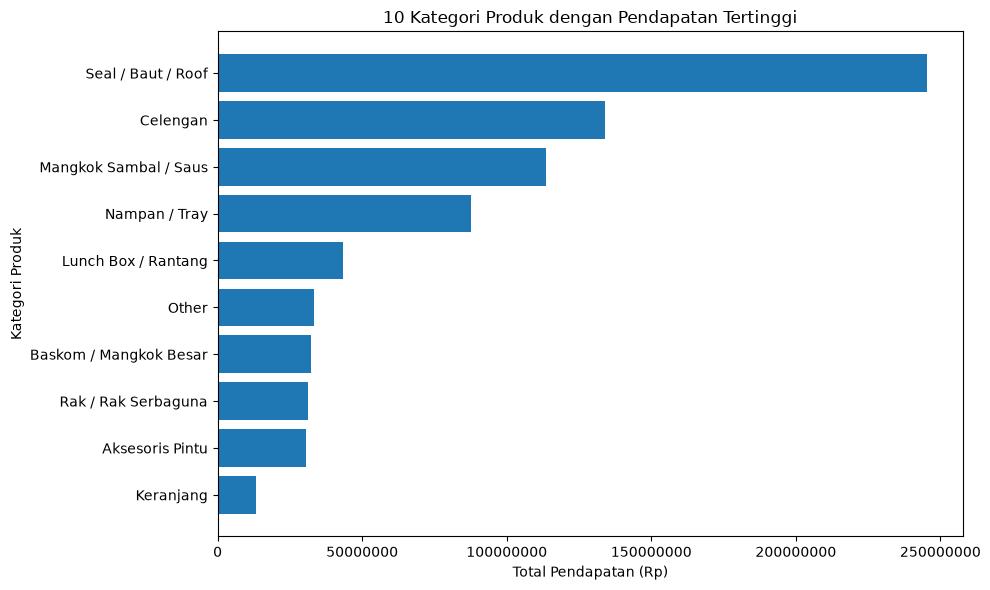

In [6]:
# Mengambil 10 kategori teratas
top_pendapatan = pendapatan_kategori.head(10).sort_values(
    "total_pendapatan"
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_pendapatan["product_categories"],
    top_pendapatan["total_pendapatan"]
)

plt.title("10 Kategori Produk dengan Pendapatan Tertinggi")
plt.xlabel("Total Pendapatan (Rp)")
plt.ylabel("Kategori Produk")
plt.ticklabel_format(
    style="plain", axis="x"
)
plt.tight_layout()
plt.show()

## 7. Visualisasi Tren Penjualan Tahunan

Grafik garis digunakan untuk menunjukkan perubahan total penjualan dari tahun ke tahun. Sumbu horizontal menunjukkan tahun transaksi dan sumbu vertikal menunjukkan total pembayaran. Grafik ini membantu mengidentifikasi kecenderungan kenaikan atau penurunan penjualan tahunan.

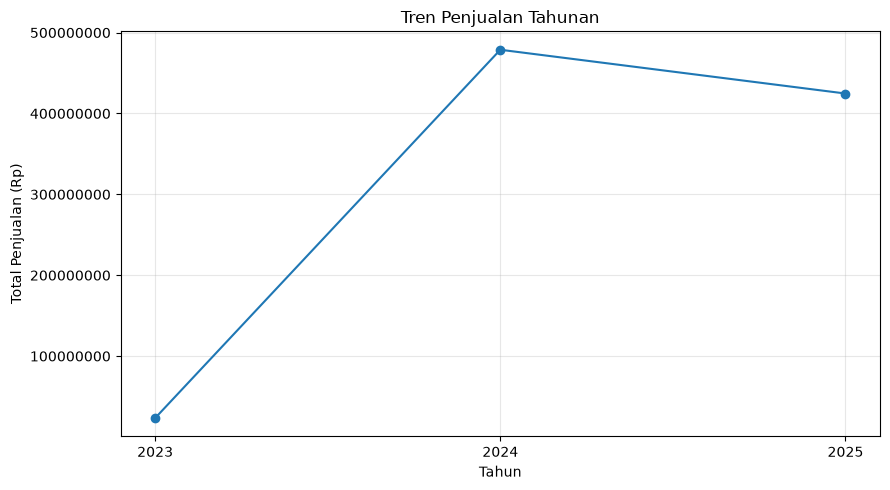

In [7]:
plt.figure(figsize=(9, 5))

plt.plot(
    tren_tahunan["tahun"],
    tren_tahunan["total_penjualan"],
    marker="o"
)

plt.title("Tren Penjualan Tahunan")
plt.xlabel("Tahun")
plt.ylabel("Total Penjualan (Rp)")
plt.xticks(tren_tahunan["tahun"])
plt.ticklabel_format(
    style="plain", axis="y"
)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Visualisasi Kategori Produk di Kabupaten Bogor

Grafik batang horizontal digunakan untuk membandingkan jumlah transaksi pada sepuluh kategori produk teratas di Kabupaten Bogor. Kategori dengan jumlah transaksi tertinggi menunjukkan produk yang paling sering muncul dalam transaksi selesai di wilayah tersebut.

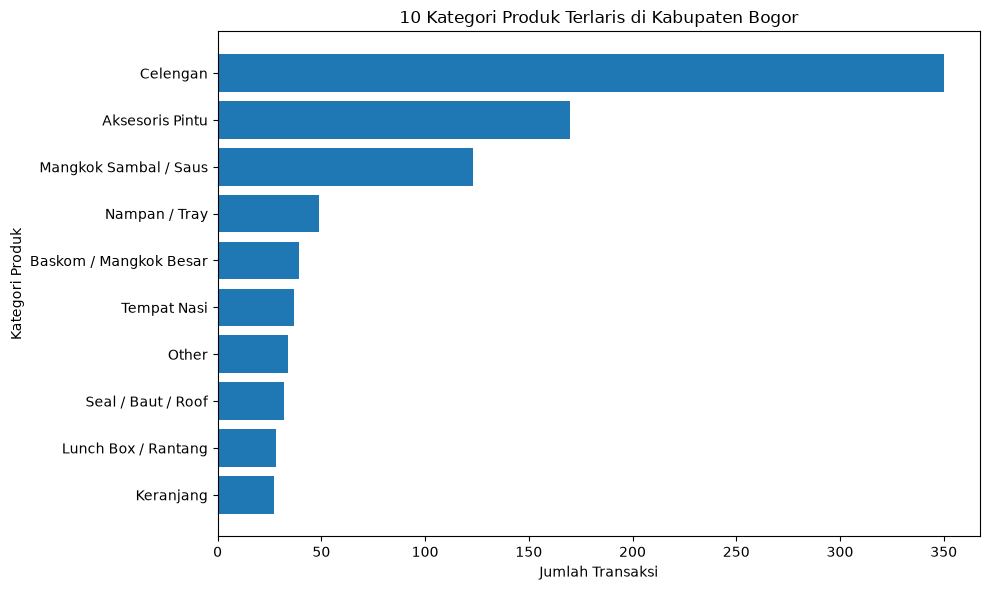

In [8]:
top_bogor = kategori_bogor.head(10).sort_values(
    "jumlah_transaksi"
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_bogor["kategori"],
    top_bogor["jumlah_transaksi"]
)

plt.title("10 Kategori Produk Terlaris di Kabupaten Bogor")
plt.xlabel("Jumlah Transaksi")
plt.ylabel("Kategori Produk")
plt.tight_layout()
plt.show()